# MNIST MLP: 8비트 양자화 실험

**노트북은 설정과 실행만**, 함수·클래스 정의는 `../src/`에서 관리합니다.

- `models.py`: assignment1의 모델 파일을 그대로 복사했습니다.
- `quantization.py`: 8비트 형식, 반올림·포화, 정수 추론을 구현합니다.
- `analysis.py`: 데이터 로딩, 평가, 시각화, 탐색과 저장을 실행합니다.

`aissd` 커널에서 위에서 아래로 실행합니다. 기본 수동 실험은 **signed Q4.4**입니다. **8번 설정 셀**을 수정하고 **9~12번 셀**을 실행하면 변경한 설정의 값·오차·정확도를 볼 수 있습니다. 환경/전처리를 바꾸면 2번부터 다시 실행합니다. 소스 파일을 수정하면 커널을 재시작하고 Run All 합니다.

weight는 항상 signed 8비트입니다. 정규화 입력과 FC3 점수는 음수가 가능하며 unsigned를 선택하면 음수가 0으로 포화됩니다. ReLU 이후 출력은 0 이상입니다. 누산기·bias는 int32이고 레이어 사이 입출력은 항상 8비트입니다.

## 1. 분석 코드 가져오기
저장소 안에서 노트북을 열면 실행 위치와 관계없이 프로젝트 소스를 찾습니다.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "project/03_model/src/analysis.py").is_file())
sys.path.insert(0, str(ROOT / "project/03_model"))
from src.analysis import MLPAnalysis
from src.quantization import make_config

## 2. 환경·데이터 설정
`preprocessing`은 `auto_calibration`, `mnist_standard`, `unit_0_1`, `minus1_plus1` 중 선택합니다. 자동 선택은 test를 사용하지 않습니다. 현재 체크포인트는 학습 calibration 비교에서 표준 정규화가 가장 높았지만 원래 학습 전처리 기록은 제공되지 않았습니다.

In [2]:
analysis = MLPAnalysis(
    seed=42,
    preprocessing="auto_calibration",
    calibration_per_digit=100,
    sample_count=10,
    batch_size=512,
    device="auto",  # "cpu" 또는 "cuda"로 지정 가능
)

Python,PyTorch,NumPy,device
3.11.16,2.11.0+cu128,2.4.6,cuda


Checkpoint: project\03_model\checkpoints\MLP_MNIST_GPU_FINAL_BEST.pth
MNIST: assignment1\data\mnist


## 3. 모델·입력 확인
모델 구조, 모든 파라미터 shape, 전처리 후보 정확도, 이미지와 픽셀 예시를 표시합니다. 표준 정규화 입력은 약 -0.424~2.821입니다.

MNISTMLP(
  (fc1): Linear(in_features=784, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


parameter,shape,dtype,count
fc1.weight,"(512, 784)",float32,401408
fc1.bias,"(512,)",float32,512
fc2.weight,"(128, 512)",float32,65536
fc2.bias,"(128,)",float32,128
fc3.weight,"(10, 128)",float32,1280
fc3.bias,"(10,)",float32,10


Total parameters: 468874
SHA-256: aaa85326d75d57f3ebe964e3cb75cff8e07a213e12fc967bf6f8b2988e3133bd


preprocessing,calibration_accuracy_%,input_min,input_max
unit_0_1,91.3,0,1
mnist_standard,99.7,-0.4242129,2.821486
minus1_plus1,80.8,-1,1


Selected using TRAIN calibration only: mnist_standard
Training preprocessing was not supplied; this is empirical selection, not proof of the original training configuration.
Normalized input can be negative: True


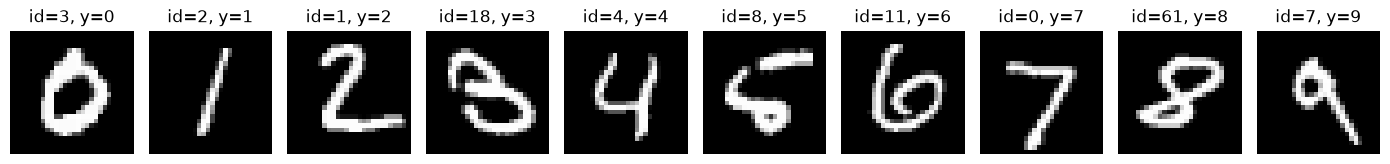

Calibration/train: 1000 | Final test: 10000
Example normalized 28x28 patch (rows 8:16, columns 8:16):
[[-0.4242129 -0.4242129  2.7960303  2.7705739  2.7705739  2.7705739  2.7705739  2.7960303]
 [-0.4242129  1.8923255  2.8214865  2.7960303  2.7960303  2.7960303  2.7960303  2.5541937]
 [ 0.3776658  2.3887267  2.7960303  2.7705739  2.7705739  2.7705739  1.4468374  0.5558611]
 [ 2.516009   2.7705739  2.7960303  2.7705739  2.3759985  1.3195552 -0.2969306 -0.4242129]
 [ 2.7705739  2.7705739  2.7960303  1.9686949 -0.1696483 -0.4242129 -0.4242129 -0.4242129]
 [ 2.7705739  2.7705739  2.1341622 -0.0423659 -0.4242129 -0.4242129 -0.4242129 -0.4242129]
 [ 2.7960303  2.7960303 -0.4242129 -0.4242129 -0.4242129 -0.4242129 -0.4242129 -0.4242129]
 [ 2.7705739  2.7705739 -0.4242129 -0.4242129 -0.4242129 -0.4242129 -0.4242129 -0.4242129]]


pixel_index,raw_uint8,unit_0_1,model_input
0,0,0,-0.4242129
1,0,0,-0.4242129
2,0,0,-0.4242129
124,11,0.04313726,-0.2842024
214,62,0.2431373,0.3649375
290,253,0.9921569,2.79603
330,5,0.01960784,-0.3605718
401,253,0.9921569,2.79603
483,217,0.8509805,2.337814
545,253,0.9921569,2.79603


In [3]:
analysis.show_model()
analysis.load_data()

## 4. FP32 기준 평가
원본 정확도, 레이어별 값 범위·음수 비율, 최종 클래스 점수를 확인합니다. 이후 비교의 기준입니다.

In [4]:
analysis.baseline()

FP32 test accuracy: 99.32%


tensor,shape,min,max,mean,std,negative_%
input,"(1000, 784)",-0.4242129,2.821486,0.007105533,1.00695,82.70459
fc1_pre_relu,"(1000, 512)",-74.47235,43.06177,-10.656,9.349939,88.69922
fc1,"(1000, 512)",0,43.06177,0.6029443,2.353128,0
fc2_pre_relu,"(1000, 128)",-68.72479,38.1567,-6.089351,10.98219,72.48438
fc2,"(1000, 128)",0,38.1567,1.953383,4.344173,0
fc3,"(1000, 10)",-36.14326,32.1205,-4.268417,9.639698,76.67


digit,test_count,accuracy_%
0,980,99.59184
1,1135,99.73568
2,1032,99.6124
3,1010,99.40594
4,982,99.59267
5,892,99.10314
6,958,98.95616
7,1028,99.12451
8,974,98.97331
9,1009,99.00892


Example final logits: [ 16.797567  -18.313911   -3.9743826  -5.844025   -0.7391288  -7.5146484  -1.326162  -11.166003   -8.637985    2.5362678]


## 5. Weight 원본 NumPy 조회
레이어·행·열을 바꿔 조회합니다. `columns=slice(None)`이면 한 행 전체를 표시합니다. 전체 배열은 `analysis.params["fc1.weight"]` 등으로 접근합니다.

In [5]:
LAYER = "fc1"  # "fc1", "fc2", "fc3"
ROW = 0
COLUMNS = slice(0, 16)
analysis.show_weights(layer=LAYER, row=ROW, columns=COLUMNS)

tensor,shape,min,max,mean,std,negative_%
fc1.weight,"(512, 784)",-1.093155,0.5471253,0.007084172,0.1002516,40.36118
fc1.bias,"(512,)",-0.1617972,0.1461218,-0.04427978,0.03834556,87.5
fc2.weight,"(128, 512)",-0.9101992,0.5172532,-0.0102341,0.109344,51.60828
fc2.bias,"(128,)",-0.3688188,0.4538631,-0.002120458,0.172333,54.6875
fc3.weight,"(10, 128)",-0.4076599,0.2356602,-0.0172193,0.103406,48.82812
fc3.bias,"(10,)",-0.4427415,0.6205183,-0.01616381,0.2578642,60


fc1.weight shape=(512, 784), row=0, columns=slice(0, 16, None)
[ 0.0084462  0.0155328  0.049722   0.0021466 -0.0011657  0.032427   0.0486942 -0.008724   0.0415146 -0.0068681  0.0497967
  0.0092673  0.0465219  0.0353285  0.0194715  0.0116065]
fc1.bias (first 16): [-0.0686161 -0.0465319 -0.0773345 -0.0360878 -0.1182983 -0.0339782 -0.0419729 -0.0621184 -0.0677825 -0.0180375 -0.0275907
 -0.0346188  0.0302591 -0.0227867 -0.0507198 -0.0114294]
Complete arrays: PARAMS["fc1.weight"], PARAMS["fc2.weight"], etc.


## 6. Weight·입출력 분포
레이어별 분포와 백분위, ReLU 이후 0 비율을 확인합니다.

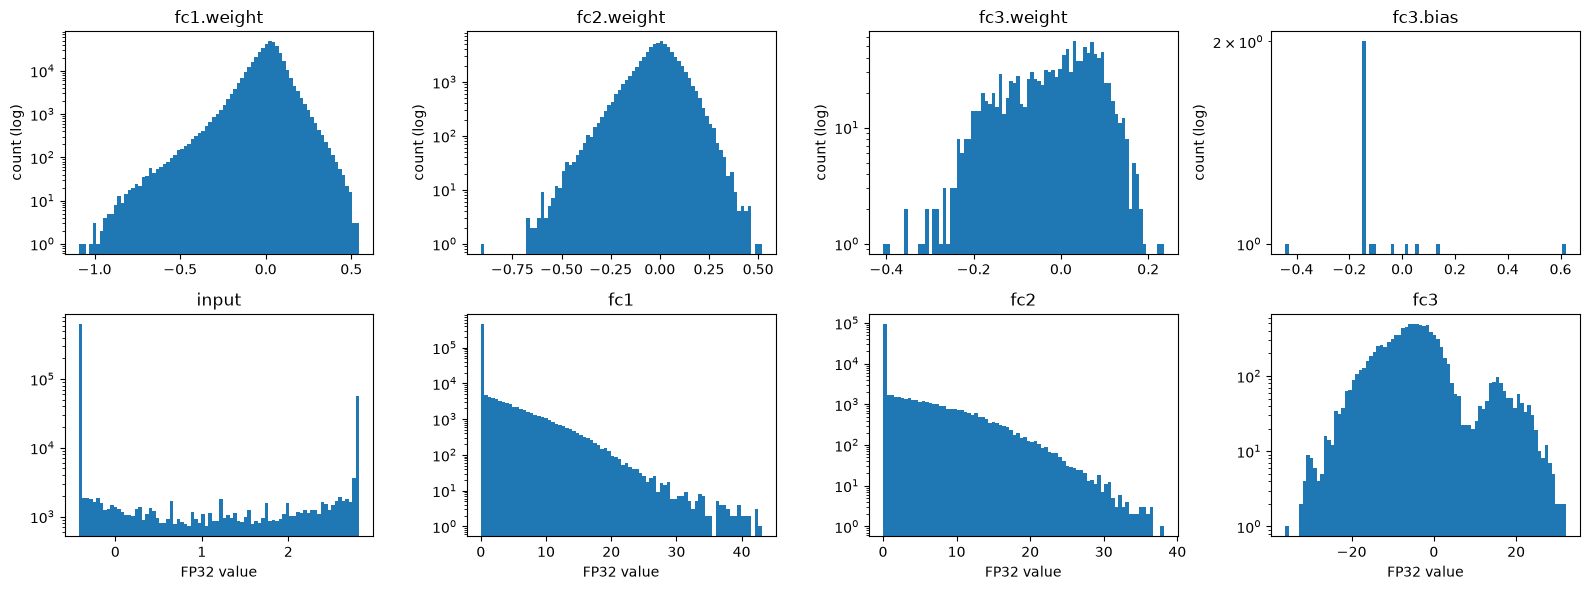

tensor,p0,p50,p99,p100,zero_%
input,-0.4242129,-0.4242129,2.808758,2.821486,0
fc1,0,0,12.65198,43.06177,88.69922
fc2,0,0,19.37114,38.1567,72.48438
fc3,-36.14326,-4.985083,23.50982,32.1205,0


In [6]:
analysis.show_distributions()

## 7. 양자화 규칙 확인
`real = code × 2^(-F)`, ties-to-even 반올림, 범위 초과 시 saturation을 사용합니다. S8/F4는 [-8, 7.9375], U8/F4는 [0, 15.9375]입니다. 경계값·음수 반올림 검사 결과를 표시합니다.

In [7]:
analysis.check_quantizer()

original,S8_F4_code,S8_F4_restored,U8_F4_code,U8_F4_restored
-9,-128,-8,0,0
-8,-128,-8,0,0
-0.09375,-2,-0.125,0,0
-0.03125,0,0,0,0
0,0,0,0,0
0.03125,0,0,0,0
0.09375,2,0.125,2,0.125
1,16,1,16,1
7.9375,127,7.9375,127,7.9375
8,127,7.9375,128,8


Boundary, saturation, and signed nearest-even checks: PASS


## 8. 직접 바꾸는 양자화 설정 — 기본 Q4.4
아래 숫자와 `True/False`를 수정한 뒤 **9~12번**을 다시 실행합니다.

- `input_frac`: 입력 소수부 비트 수
- `weight_frac`: 모든 레이어 공통 정수 또는 `(FC1, FC2, FC3)` 튜플. 예: `(6, 7, 7)`
- `output_frac`: 공통 정수 또는 레이어별 튜플
- `input_signed`, `output_signed`: signed는 `True`, unsigned는 `False`
- `hidden_signed`: FC1/FC2 ReLU 출력 부호. 공통 bool 또는 `(True, False)`처럼 지정

전체 비트 수는 모두 8비트로 고정입니다. F를 늘리면 간격은 줄지만 범위가 좁아집니다. 비교를 남기려면 `EXPERIMENT_NAME`을 바꾸고 12번 셀을 실행합니다. 같은 이름은 현재 결과로 갱신합니다. `EVAL_SPLIT="calibration"`이면 학습 표본, `"test"`이면 test 10,000장으로 평가합니다.

In [8]:
manual_config = make_config(
    input_frac=4,
    weight_frac=4,           # 또는 (6, 7, 7)
    output_frac=(4, 4, 4),
    input_signed=True,
    hidden_signed=True,     # False: ReLU 이후 출력 unsigned
    output_signed=True,     # False: 최종 점수 unsigned 강제 실험
)
EXPERIMENT_NAME = "manual_Q4.4"
EVAL_SPLIT = "test"

## 9. 입력 양자화 예시
선택한 입력 형식과 비교 형식들의 이미지·오차·정수 코드를 표시합니다. 화면에는 입력 몇 개만 표시합니다. 음수 코드의 비트 표시는 2의 보수입니다.

format,min_repr,max_repr,step,MAE,MSE,max_error,outside_%,saturation_%,zero_%
S8/F4,-8,7.9375,0.0625,0.01373717,0.0002048815,0.03119493,0,0,0.2289541
S8/F5,-4,3.96875,0.03125,0.01231046,0.0001602968,0.01556939,0,0,0.07079082
S8/F6,-2,1.984375,0.015625,0.07757748,0.05737936,0.8371115,10.93661,10.93661,0.03086735
U8/F7,0,1.992188,0.0078125,0.4211704,0.2025456,0.829299,93.6412,93.59541,82.70459
U8/F8,0,0.9960938,0.00390625,0.5451156,0.4693575,1.825393,96.74809,96.74809,82.70459


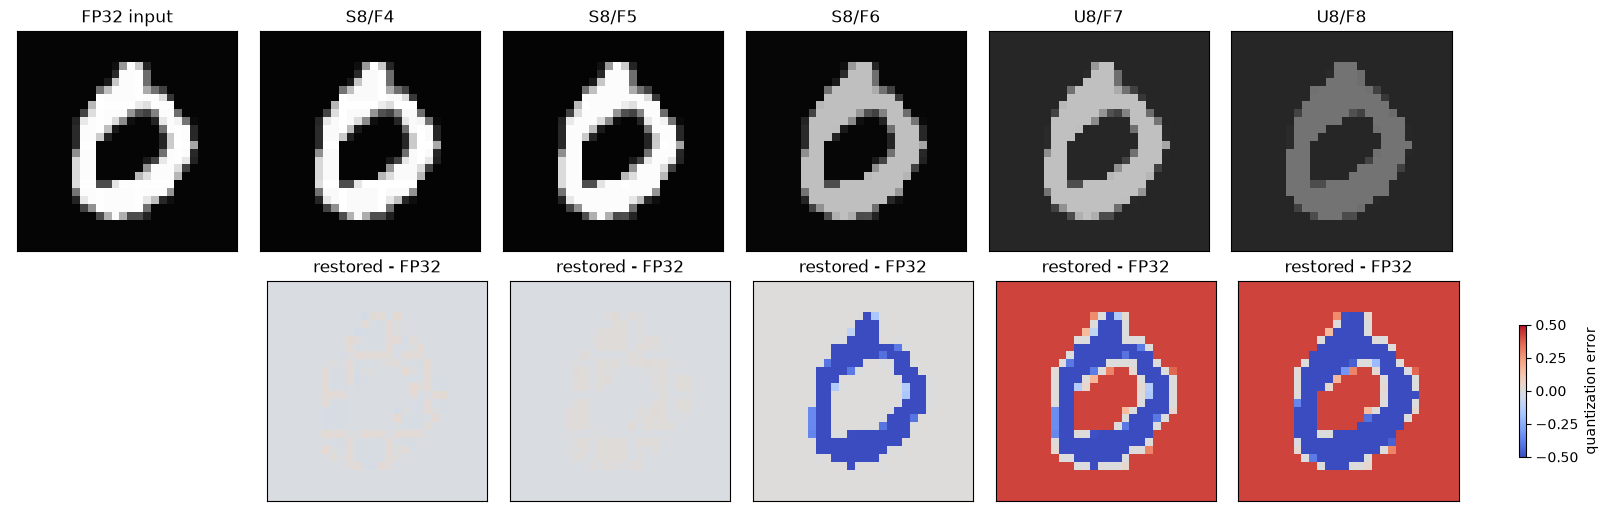

pixel,original,code8,bits,restored
0,-0.4242129,-7,11111001,-0.4375
1,-0.4242129,-7,11111001,-0.4375
2,-0.4242129,-7,11111001,-0.4375
124,-0.2842024,-5,11111011,-0.3125
214,0.3649375,6,00000110,0.375
290,2.79603,45,00101101,2.8125
330,-0.3605718,-6,11111010,-0.375
401,2.79603,45,00101101,2.8125
483,2.337814,37,00100101,2.3125
545,2.79603,45,00101101,2.8125


Unsigned model-input quantization is diagnostic when normalization produces negative inputs.


In [9]:
analysis.show_input_quantization(manual_config)

## 10. Weight 양자화 예시
선택한 형식의 weight 코드·복원값과 소수부 변경 시 오차를 표시합니다. 조회 레이어와 행은 5번 셀의 선택을 따릅니다.

layer,format,min_repr,max_repr,step,MAE,MSE,max_error,outside_%,saturation_%,zero_%
fc1,S8/F4,-8,7.9375,0.0625,0.01562577,0.0003257969,0.03124994,0,0,30.48768
fc1,S8/F5,-4,3.96875,0.03125,0.007796865,8.114351e-05,0.01562499,0,0,15.45036
fc1,S8/F6,-2,1.984375,0.015625,0.003904164,2.032005e-05,0.007812448,0,0,7.755451
fc1,S8/F7,-1,0.9921875,0.0078125,0.001955658,5.128815e-06,0.09315479,0.0009964923,0.0009964923,3.928671
fc2,S8/F4,-8,7.9375,0.0625,0.01567237,0.0003264085,0.03124922,0,0,28.57666
fc2,S8/F5,-4,3.96875,0.03125,0.007848978,8.192761e-05,0.01562467,0,0,14.75372
fc2,S8/F6,-2,1.984375,0.015625,0.003904467,2.029462e-05,0.007812463,0,0,7.337952
fc2,S8/F7,-1,0.9921875,0.0078125,0.001960473,5.107163e-06,0.003906168,0,0,3.762817
fc3,S8/F4,-8,7.9375,0.0625,0.01564232,0.0003265406,0.03123043,0,0,20.85938
fc3,S8/F5,-4,3.96875,0.03125,0.007825682,8.227068e-05,0.01560906,0,0,10.85938


column,original,F4_code,F6_code,F7_code,F4_restored,F6_restored,F7_restored
0,0.008446173,0,1,1,0,0.015625,0.0078125
1,0.01553278,0,1,2,0,0.015625,0.015625
2,0.04972202,1,3,6,0.0625,0.046875,0.046875
3,0.00214662,0,0,0,0,0,0
4,-0.001165691,0,0,0,0,0,0
5,0.03242697,1,2,4,0.0625,0.03125,0.03125
6,0.04869422,1,3,6,0.0625,0.046875,0.046875
7,-0.008724041,0,-1,-1,0,-0.015625,-0.0078125
8,0.04151465,1,3,5,0.0625,0.046875,0.0390625
9,-0.006868088,0,0,-1,0,0,-0.0078125


column,original,current_format,current_code8,current_restored
0,0.008446173,S8/F4,0,0
1,0.01553278,S8/F4,0,0
2,0.04972202,S8/F4,1,0.0625
3,0.00214662,S8/F4,0,0
4,-0.001165691,S8/F4,0,0
5,0.03242697,S8/F4,1,0.0625
6,0.04869422,S8/F4,1,0.0625
7,-0.008724041,S8/F4,0,0
8,0.04151465,S8/F4,1,0.0625
9,-0.006868088,S8/F4,0,0


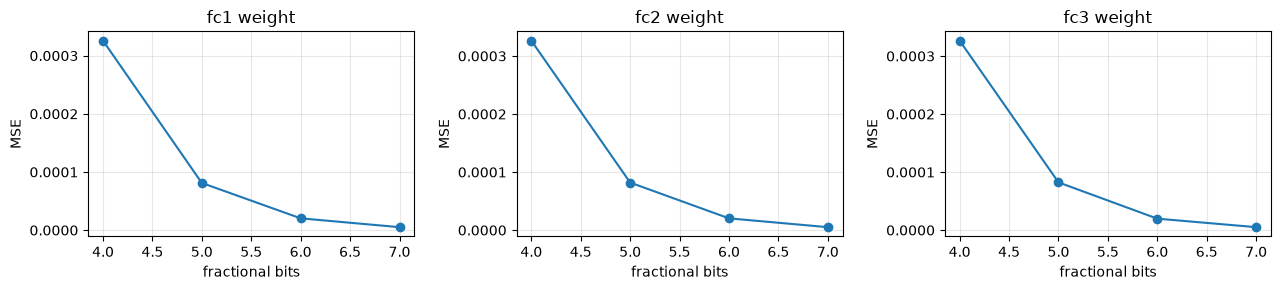

In [10]:
analysis.show_weight_quantization(manual_config)

## 11. 레이어별 실제 8비트 전달 값
선택한 설정으로 입력 → FC1 → FC2 → FC3를 추론합니다. 레이어별 코드·복원값·포화율 및 최종 클래스 점수를 보여주고 CPU int64 계산과 대조합니다.

행렬 곱은 부분합의 절댓값 상한이 int32 범위임을 확인한 뒤 float64로 정확하게 가속하고 int32로 변환합니다. 출력 재양자화는 2의 거듭제곱 스케일·반올림·포화 순서입니다. FPGA 성능을 측정하는 코드는 아닙니다.

In [11]:
analysis.show_pipeline(manual_config)

layer,format,acc_abs_bound,saturation_%,local_MSE
fc1,S8/F4,62816,2.851563,1.053738
fc2,S8/F4,109625,5.625,0.8177552
fc3,S8/F4,25937,15,0.906297


input S8/F4 torch.int8 | codes: [-7 -7 -7 -7 -7 -7 -7 -7 -7 -7 -7 -7] | restored: [-0.4375 -0.4375 -0.4375 -0.4375 -0.4375 -0.4375 -0.4375 -0.4375 -0.4375 -0.4375 -0.4375 -0.4375]
fc1 S8/F4 torch.int8 | codes: [0 0 0 0 0 0 0 0 0 0 0 0] | restored: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
fc2 S8/F4 torch.int8 | codes: [  0   0   0   2  47   0   0   0 125 113   0   0] | restored: [0.     0.     0.     0.125  2.9375 0.     0.     0.     7.8125 7.0625 0.     0.    ]
fc3 S8/F4 torch.int8 | codes: [ 127 -128  -65  -52    6  -74   -8 -106  -85   30] | restored: [ 7.9375 -8.     -4.0625 -3.25    0.375  -4.625  -0.5    -6.625  -5.3125  1.875 ]


class,FP32_logit,code8,restored
0,16.79757,127,7.9375
1,-18.31391,-128,-8
2,-3.974383,-65,-4.0625
3,-5.844025,-52,-3.25
4,-0.7391288,6,0.375
5,-7.514648,-74,-4.625
6,-1.326162,-8,-0.5
7,-11.166,-106,-6.625
8,-8.637985,-85,-5.3125
9,2.536268,30,1.875


CPU int64 equivalence and 8-bit stage dtype checks: PASS


## 12. 내가 설정한 형식의 정확도
선택한 형식으로 정확도·FP32 대비 하락·예측 변경·레이어 포화율을 확인합니다. 8번 설정만 바꿔도 기본 모델을 다시 로드할 필요는 없습니다. 8번과 이 셀만 실행하면 정확도를 빠르게 비교할 수 있습니다. 형식 선택에는 calibration을 사용하고 test는 최종 비교용으로 사용하는 것을 권장합니다.

In [12]:
manual_result = analysis.run_experiment(manual_config, name=EXPERIMENT_NAME, split=EVAL_SPLIT)

phase,experiment,accuracy_%,prediction_changed_%,logit_MSE,argmax_tie_%,config,fc1_saturation_%,fc2_saturation_%,fc3_saturation_%,seconds,drop_pp
test,manual_Q4.4,98.99,0.63,34.96278,0.03,"S8/F4|W:4,4,4|A:S8/F4,S8/F4,S8/F4",2.685762,6.130937,22.668,0.1139087,0.33


## 13. 선택 사항: 소수점 위치 자동 탐색
고정 Q4.4 기준 비교와 텐서별 국소 MSE 탐색을 수행합니다. 자동 탐색은 8번의 수동 설정을 덮어쓰지 않습니다. weight와 signed 출력은 F=0~7, unsigned 활성값은 F=0~8을 비교합니다.

phase,experiment,accuracy_%,prediction_changed_%,logit_MSE,argmax_tie_%,config,fc1_saturation_%,fc2_saturation_%,fc3_saturation_%,seconds,drop_pp
calibration,FP32,99.7,,,,,,,,,
test,manual_Q4.4,98.99,0.63,34.96278,0.03,"S8/F4|W:4,4,4|A:S8/F4,S8/F4,S8/F4",2.685762,6.130937,22.668,0.1139087,0.33
calibration,q44_signed,99.3,0.4,34.05324,0.2,"S8/F4|W:4,4,4|A:S8/F4,S8/F4,S8/F4",2.680469,6.134375,22.56,0.0113148,
calibration,q44_unsigned_positive,98.7,1,29.08959,1.8,"S8/F4|W:4,4,4|A:U8/F4,U8/F4,S8/F4",0.4646484,1.884375,42.4,0.0123849,


Calibration scores only; final test comparison is shown in the final evaluation stage.


profile,initial_config
signed,"S8/F5|W:7,7,7|A:S8/F1,S8/F2,S8/F2"
unsigned_positive,"S8/F5|W:7,7,7|A:U8/F2,U8/F2,S8/F2"


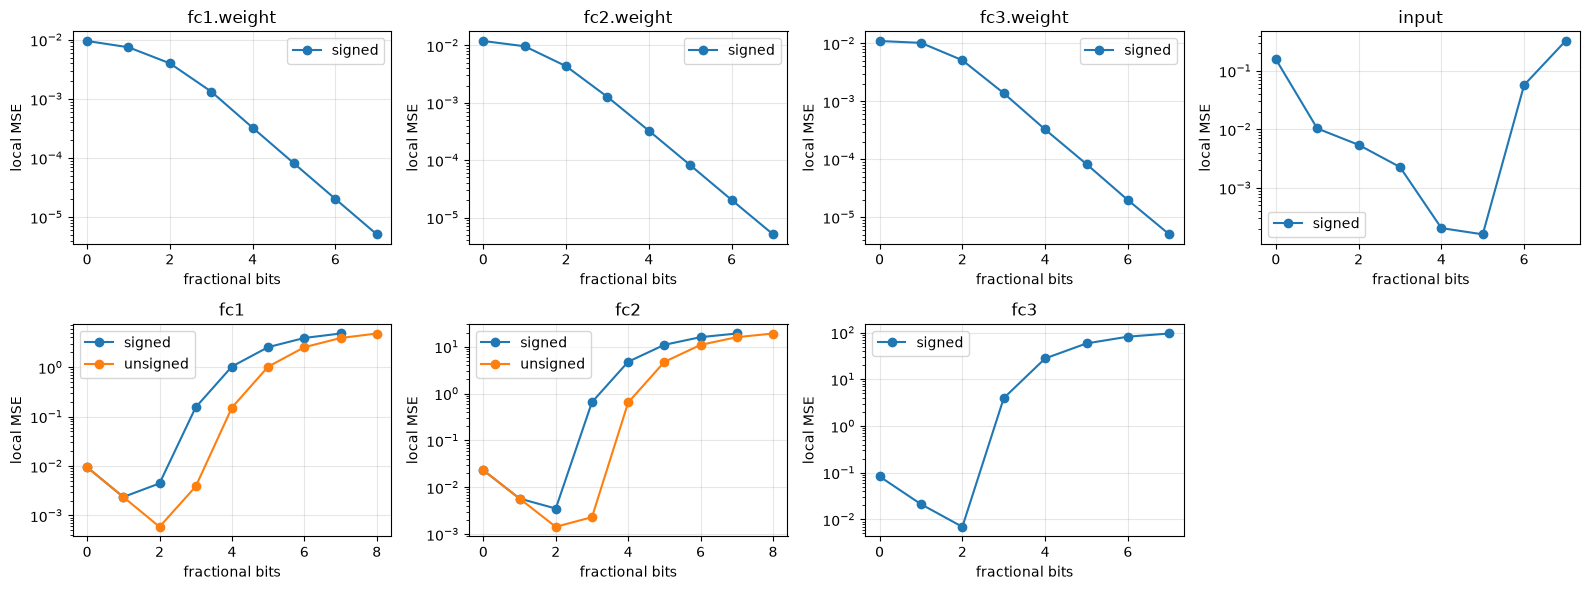

Complete local search records: 90 (variable: format_search_rows)


In [13]:
analysis.compare_q44()
analysis.search_formats()

## 14. 선택 사항: signed·unsigned 자동 후보 비교
학습 calibration에서 입력·레이어 출력 F를 한 번씩 인접 탐색합니다. calibration 정확도 우선, 동률이면 점수 MSE 우선입니다. 전역 최적값을 보장하지 않습니다. 음수 입력/최종 출력을 unsigned로 강제한 진단도 표시합니다.

In [14]:
analysis.compare_auto()

Selected on calibration: signed S8/F5|W:7,7,7|A:S8/F1,S8/F2,S8/F2


Selected on calibration: unsigned_positive S8/F5|W:7,7,7|A:U8/F2,U8/F2,S8/F2


profile,phase,experiment,accuracy_%,prediction_changed_%,logit_MSE,argmax_tie_%,config,fc1_saturation_%,fc2_saturation_%,fc3_saturation_%,seconds
signed,calibration,signed_seed,99.7,0,0.06437164,0,"S8/F5|W:7,7,7|A:S8/F1,S8/F2,S8/F2",0,0.0234375,0.02,0.0131376
unsigned_positive,calibration,unsigned_positive_seed,99.7,0,0.05064864,0.1,"S8/F5|W:7,7,7|A:U8/F2,U8/F2,S8/F2",0,0,0.04,0.0121167
unsigned final (diagnostic),calibration,unsigned_final_DIAGNOSTIC,99.7,0,77.9787,0.1,"S8/F5|W:7,7,7|A:U8/F2,U8/F2,U8/F2",0,0,75.74,0.0133399
unsigned input (diagnostic),calibration,unsigned_input_DIAGNOSTIC,88.9,10.8,23.96054,0.5,"U8/F5|W:7,7,7|A:U8/F2,U8/F2,S8/F2",0,0,0.1,0.0125555


Configurations frozen before final test evaluation.


## 15. 선택 사항: 최종 test 비교
13~14번 실행 후 사용합니다. 자동 후보와 현재 수동 형식을 test에서 비교하고 숫자별 정확도와 오분류 예시를 표시합니다. 추천 후보는 calibration 결과로 정하며 test에서 재선택하지 않습니다.

phase,experiment,accuracy_%,prediction_changed_%,logit_MSE,argmax_tie_%,config,fc1_saturation_%,fc2_saturation_%,fc3_saturation_%,seconds,drop_pp
test,FP32,99.32,0,0,,,,,,,
test,q44_signed,98.99,0.63,34.96278,0.03,"S8/F4|W:4,4,4|A:S8/F4,S8/F4,S8/F4",2.685762,6.130937,22.668,0.1053389,0.33
test,q44_unsigned_positive,98.66,0.85,29.96801,1.39,"S8/F4|W:4,4,4|A:U8/F4,U8/F4,S8/F4",0.4599023,1.911484,42.426,0.1037298,0.66
test,selected_signed,99.28,0.05,0.07666546,0.05,"S8/F5|W:7,7,7|A:S8/F1,S8/F2,S8/F2",0,0.02960938,0.106,0.1063893,0.04
test,selected_unsigned_positive,99.27,0.06,0.05693926,0.06,"S8/F5|W:7,7,7|A:U8/F2,U8/F2,S8/F2",0,0,0.114,0.1044745,0.05
test,unsigned_final_DIAGNOSTIC,99.27,0.06,79.33235,0.06,"S8/F5|W:7,7,7|A:U8/F2,U8/F2,U8/F2",0,0,75.743,0.1041429,0.05
test,unsigned_input_DIAGNOSTIC,88.83,11,23.95946,0.44,"U8/F5|W:7,7,7|A:U8/F2,U8/F2,S8/F2",0,0,0.158,0.1040469,10.49
test,manual_Q4.4,98.99,0.63,34.96278,0.03,"S8/F4|W:4,4,4|A:S8/F4,S8/F4,S8/F4",2.685762,6.130937,22.668,0.1030928,0.33


Recommended by calibration: unsigned_positive S8/F5|W:7,7,7|A:U8/F2,U8/F2,S8/F2


digit,FP32_accuracy_%,INT8_accuracy_%
0,99.59184,99.4898
1,99.73568,99.64758
2,99.6124,99.6124
3,99.40594,99.40594
4,99.59267,99.59267
5,99.10314,99.10314
6,98.95616,98.85177
7,99.12451,99.02724
8,98.97331,98.97331
9,99.00892,98.90981


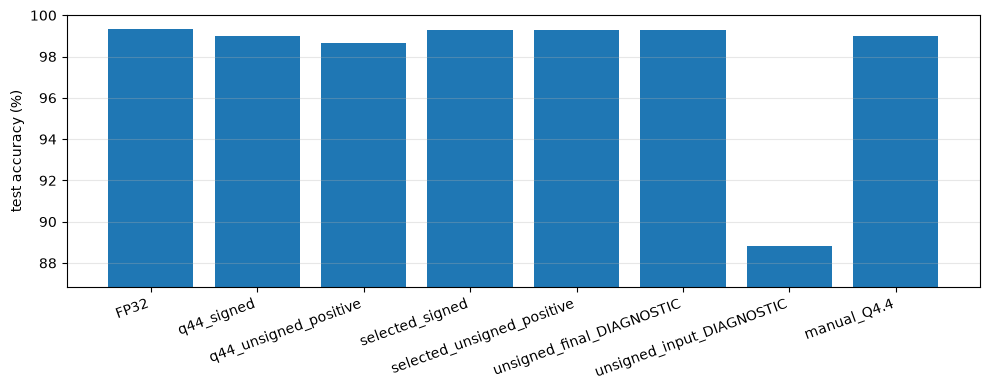

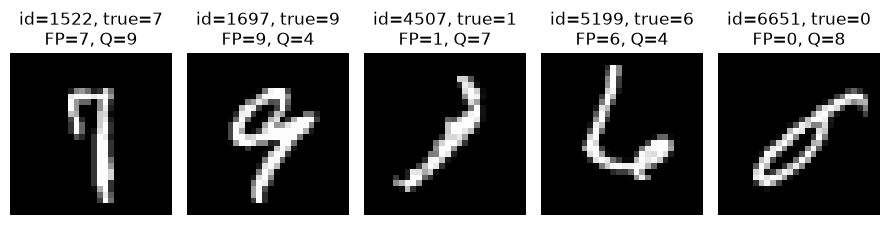

sample_id,class,FP32_logit,INT8_restored_logit
1522,0,-16.7127,-16.5
1522,1,4.729341,4.5
1522,2,-3.980288,-4.25
1522,3,-5.236256,-5.25
1522,4,-0.2594807,-0.25
1522,5,-9.152247,-9.25
1522,6,-16.82601,-16.75
1522,7,6.708822,6.25
1522,8,-2.982597,-3
1522,9,6.501948,6.75


Selected signed/unsigned CPU integer equivalence and all 8-bit stage checks: PASS


In [15]:
analysis.evaluate_final()

## 16. 선택한 형식의 전체 weight·예시 입출력 저장
기본 저장 대상은 **8번에서 직접 설정한 형식**입니다. 자동 추천을 저장하려면 `EXPORT_CONFIG = analysis.recommended_config`로 바꿉니다(13~15번 실행 필요).

`07_runs/mlp_int8_analysis/arrays.npz`에 원본 전체 weight·bias, 선택한 형식의 weight·bias와 예시 입출력을 저장하고 `results.csv`에 비교표를 저장합니다. 설정과 전처리도 NPZ metadata에 포함됩니다. 두 파일은 재실행 시 갱신되며 Git에서 제외됩니다. 자동 탐색 셀을 건너뛰어도 수동 설정은 저장할 수 있습니다.

In [16]:
EXPORT_CONFIG = manual_config  # 자동 추천: analysis.recommended_config
analysis.save_results(EXPORT_CONFIG, name=EXPERIMENT_NAME)

Saved and verified: D:\Data\Local\Desktop\programing\AISSD\project\07_runs\mlp_int8_analysis\arrays.npz
Saved: D:\Data\Local\Desktop\programing\AISSD\project\07_runs\mlp_int8_analysis\results.csv


array,shape,dtype
original__fc1__weight,"(512, 784)",float32
original__fc1__bias,"(512,)",float32
original__fc2__weight,"(128, 512)",float32
original__fc2__bias,"(128,)",float32
original__fc3__weight,"(10, 128)",float32
original__fc3__bias,"(10,)",float32
quantized__fc1__weight,"(512, 784)",int8
quantized__fc1__bias_int32,"(512,)",int32
quantized__fc2__weight,"(128, 512)",int8
quantized__fc2__bias_int32,"(128,)",int32


Load: saved = np.load(analysis.result_dir / "arrays.npz", allow_pickle=False)
All FC1 weights: saved["original__fc1__weight"]
Quantized FC1 weights: saved["quantized__fc1__weight"]


숫자를 다시 불러오려면 `np.load(analysis.result_dir / "arrays.npz", allow_pickle=False)`를 사용합니다. `original__fc1__weight`는 원본 전체 행렬, `quantized__fc1__weight`는 선택한 형식의 int8 전체 행렬입니다. `metadata_json`에 실제 export 설정이 기록됩니다. RTL에서는 스케일·반올림·포화·argmax 동점 규칙을 그대로 맞춰야 합니다.